In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv('Bookings(1).csv')
pd.set_option('display.max_columns',None)

In [4]:
df.head()

,Date,Time,Booking_ID,Booking_Status,Customer_ID,Vehicle_Type,Pickup_Location,Drop_Location,Weather,V_TAT,C_TAT,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Incomplete_Rides,Incomplete_Rides_Reason,Booking_Value,Payment_Method,Ride_Distance,Driver_Ratings,Customer_Rating
0,26-07-2024,14:00:00,CNR7153255142,Canceled by Driver,CID713523,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,NaN,NaN,NaN,Personal & Car related issue,NaN,NaN,389,NaN,16,NaN,NaN
1,25-07-2024,22:20:00,CNR2940424040,Success,CID225428,Bike,Magadi Road,Varthur,Cloudy,203.0,30.0,NaN,NaN,No,NaN,94,Cash,13,4.1,4.0
2,30-07-2024,19:59:00,CNR2982357879,Success,CID270156,Prime SUV,Sahakar Nagar,Varthur,Cloudy,238.0,130.0,NaN,NaN,No,NaN,1547,UPI,40,4.2,4.8
3,22-07-2024,03:15:00,CNR2395710036,Canceled by Customer,CID581320,eBike,HSR Layout,Vijayanagar,Clear,NaN,NaN,Driver is not moving towards pickup location,NaN,NaN,NaN,138,NaN,18,NaN,NaN
4,02-07-2024,09:02:00,CNR1797421769,Success,CID939555,Mini,Rajajinagar,Chamarajpet,Light Rain,252.0,80.0,NaN,NaN,No,NaN,1056,Credit Card,45,4.0,3.0


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 103024 entries, 0 to 103023
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype  
---  ------                      --------------   -----  
 0   Date                        103024 non-null  object 
 1   Time                        103024 non-null  object 
 2   Booking_ID                  103024 non-null  object 
 3   Booking_Status              103024 non-null  object 
 4   Customer_ID                 103024 non-null  object 
 5   Vehicle_Type                103024 non-null  object 
 6   Pickup_Location             103024 non-null  object 
 7   Drop_Location               103024 non-null  object 
 8   Weather                     103024 non-null  object 
 9   V_TAT                       63967 non-null   float64
 10  C_TAT                       63967 non-null   float64
 11  Canceled_Rides_by_Customer  10499 non-null   object 
 12  Canceled_Rides_by_Driver    18434 non-null   object 
 13  Incomplete_Rid

In [6]:
df = df[['Date','Time','Vehicle_Type','Pickup_Location','Drop_Location','Weather','Booking_Value','Ride_Distance']]

In [7]:
df.head()

,Date,Time,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance
0,26-07-2024,14:00:00,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,389,16
1,25-07-2024,22:20:00,Bike,Magadi Road,Varthur,Cloudy,94,13
2,30-07-2024,19:59:00,Prime SUV,Sahakar Nagar,Varthur,Cloudy,1547,40
3,22-07-2024,03:15:00,eBike,HSR Layout,Vijayanagar,Clear,138,18
4,02-07-2024,09:02:00,Mini,Rajajinagar,Chamarajpet,Light Rain,1056,45


In [8]:
df.isnull().sum()

Date               0
Time               0
Vehicle_Type       0
Pickup_Location    0
Drop_Location      0
Weather            0
Booking_Value      0
Ride_Distance      0
dtype: int64

In [9]:
df.duplicated().sum()

np.int64(2)

In [10]:
df.drop_duplicates(inplace =True)

In [11]:
df.describe()

,Booking_Value,Ride_Distance
count,103022.000000,103022.000000
mean,414.988255,20.348120
std,367.886525,13.179432
min,28.000000,1.000000
25%,146.000000,10.000000
50%,271.000000,18.000000
75%,595.000000,29.000000
max,2437.000000,61.000000


In [12]:
df[df['Booking_Value'] == 2437.000000]

,Date,Time,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance
14051,23-07-2024,17:42:00,Prime SUV,Banashankari,Jayanagar,Heavy Rain,2437,49


In [13]:
df[df['Booking_Value']>1500]

,Date,Time,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance
2,30-07-2024,19:59:00,Prime SUV,Sahakar Nagar,Varthur,Cloudy,1547,40
118,15-07-2024,09:20:00,Prime SUV,Mysore Road,Peenya,Light Rain,2189,49
166,14-07-2024,16:42:00,Prime SUV,MG Road,BTM Layout,Heavy Rain,1643,45
204,30-07-2024,18:06:00,Prime Plus,Hennur,Hosur Road,Cloudy,1569,48
260,09-07-2024,18:33:00,Prime SUV,Indiranagar,Basavanagudi,Light Rain,1822,43
...,...,...,...,...,...,...,...,...
102676,31-07-2024,09:10:00,Prime SUV,Cox Town,Richmond Town,Cloudy,1838,48
102688,31-07-2024,10:36:00,Prime SUV,Sahakar Nagar,Hennur,Cloudy,1583,41
102758,31-07-2024,19:52:00,Prime SUV,Shantinagar,BTM Layout,Cloudy,1843,47
102846,31-07-2024,19:47:00,Prime Plus,Tumkur Road,HSR Layout,Cloudy,1637,49


In [14]:
df.groupby(['Vehicle_Type']).agg({
    'Booking_Value':['min', 'max', 'mean']
})

Booking_Value                  
                       min   max        mean
Vehicle_Type                                
Auto                    38   918  164.206181
Bike                    28   476  162.843132
Mini                    66  1394  423.950041
Prime Plus             114  2318  667.132726
Prime SUV              142  2437  780.701945
Prime Sedan             95  1931  556.975331
eBike                   28   474  150.824502

In [15]:
df[(df['Vehicle_Type'] == 'Auto') & (df['Booking_Value'] > 600)].head()

,Date,Time,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance
5986,15-07-2024,21:01:00,Auto,Devanahalli,Hulimavu,Light Rain,637,57
10058,16-07-2024,08:36:00,Auto,Sarjapur Road,Devanahalli,Light Rain,676,51
11309,23-07-2024,19:31:00,Auto,Devanahalli,Koramangala,Heavy Rain,746,49
12620,03-07-2024,08:19:00,Auto,Devanahalli,Hosur Road,Cloudy,613,54
16068,26-07-2024,18:13:00,Auto,Chamarajpet,Devanahalli,Light Rain,697,48


* This Booking Value price quite normal on tha basis of ride distance

In [16]:
df[(df['Vehicle_Type'].isin(['Auto','Bike','Mini','eBike'])) & (df['Booking_Value'] < 100)].shape[0]

13648

* Auto,Bike,Mini,eBike all vehicle have efficent number of values in less than 100 

In [17]:
from datetime import datetime
x = datetime.now()
x_str = x.strftime('%Y-%m-%d %H:%M:%S')
print(x_str)

2026-10-09 19:48:18


In [18]:
df['Date'] = df['Date'] + " " + df['Time']

In [19]:
df.drop(columns=['Time'],inplace=True)

In [20]:
df.head()

,Date,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance
0,26-07-2024 14:00:00,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,389,16
1,25-07-2024 22:20:00,Bike,Magadi Road,Varthur,Cloudy,94,13
2,30-07-2024 19:59:00,Prime SUV,Sahakar Nagar,Varthur,Cloudy,1547,40
3,22-07-2024 03:15:00,eBike,HSR Layout,Vijayanagar,Clear,138,18
4,02-07-2024 09:02:00,Mini,Rajajinagar,Chamarajpet,Light Rain,1056,45


In [21]:
df['Date'] = pd.to_datetime(df['Date'])

C:\Users\SAYAN\AppData\Local\Temp\ipykernel_1528\2394721818.py:1: UserWarning: Parsing dates in %d-%m-%Y %H:%M:%S format when dayfirst=False (the default) was specified. Pass `dayfirst=True` or specify a format to silence this warning.
  df['Date'] = pd.to_datetime(df['Date'])


In [22]:
df['booking_hour'] = df['Date'].dt.hour
df['booking_dayofweek'] = df["Date"].dt.day_name()

In [23]:
df['office_hour'] = np.where(
    ((df['booking_hour'] >= 9) & (df['booking_hour'] <= 12)) | ((df['booking_hour'] >= 17) & (df['booking_hour'] <= 20)), 
    'Yes', 'No'
)

In [24]:
df.head()

,Date,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance,booking_hour,booking_dayofweek,office_hour
0,2024-07-26 14:00:00,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,389,16,14,Friday,No
1,2024-07-25 22:20:00,Bike,Magadi Road,Varthur,Cloudy,94,13,22,Thursday,No
2,2024-07-30 19:59:00,Prime SUV,Sahakar Nagar,Varthur,Cloudy,1547,40,19,Tuesday,Yes
3,2024-07-22 03:15:00,eBike,HSR Layout,Vijayanagar,Clear,138,18,3,Monday,No
4,2024-07-02 09:02:00,Mini,Rajajinagar,Chamarajpet,Light Rain,1056,45,9,Tuesday,Yes


In [25]:
weekend_days = ['Saturday', 'Sunday']
df['is_weekend'] = df['booking_dayofweek'].isin(weekend_days).map({True: 'Yes', False: 'No'})

In [26]:
df.head(2)

,Date,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance,booking_hour,booking_dayofweek,office_hour,is_weekend
0,2024-07-26 14:00:00,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,389,16,14,Friday,No,No
1,2024-07-25 22:20:00,Bike,Magadi Road,Varthur,Cloudy,94,13,22,Thursday,No,No


In [27]:
def marge_pickup_drop(pickup,drop):
    return pickup + '_' + drop

In [28]:
df['Pickup&Drop_Location'] = df.apply(lambda row: marge_pickup_drop(row['Pickup_Location'], row['Drop_Location']), axis=1)

In [29]:
df.head()

,Date,Vehicle_Type,Pickup_Location,Drop_Location,Weather,Booking_Value,Ride_Distance,booking_hour,booking_dayofweek,office_hour,is_weekend,Pickup&Drop_Location
0,2024-07-26 14:00:00,Prime Sedan,Tumkur Road,RT Nagar,Light Rain,389,16,14,Friday,No,No,Tumkur Road_RT Nagar
1,2024-07-25 22:20:00,Bike,Magadi Road,Varthur,Cloudy,94,13,22,Thursday,No,No,Magadi Road_Varthur
2,2024-07-30 19:59:00,Prime SUV,Sahakar Nagar,Varthur,Cloudy,1547,40,19,Tuesday,Yes,No,Sahakar Nagar_Varthur
3,2024-07-22 03:15:00,eBike,HSR Layout,Vijayanagar,Clear,138,18,3,Monday,No,No,HSR Layout_Vijayanagar
4,2024-07-02 09:02:00,Mini,Rajajinagar,Chamarajpet,Light Rain,1056,45,9,Tuesday,Yes,No,Rajajinagar_Chamarajpet


In [30]:
df = df.drop(columns= ['Pickup_Location','Drop_Location'])

# Univariate Analysis

In [31]:
num_cols = df.select_dtypes(np.number).columns
cat_cols = [c for c in df.select_dtypes(include=['object']).columns if c != 'Pickup&Drop_Location']

In [32]:
print(f'numerical columns: ',num_cols)
print()
print(f'categorical columns: ',cat_cols)

numerical columns:  Index(['Booking_Value', 'Ride_Distance', 'booking_hour'], dtype='object')

categorical columns:  ['Vehicle_Type', 'Weather', 'booking_dayofweek', 'office_hour', 'is_weekend']


## Numerical 

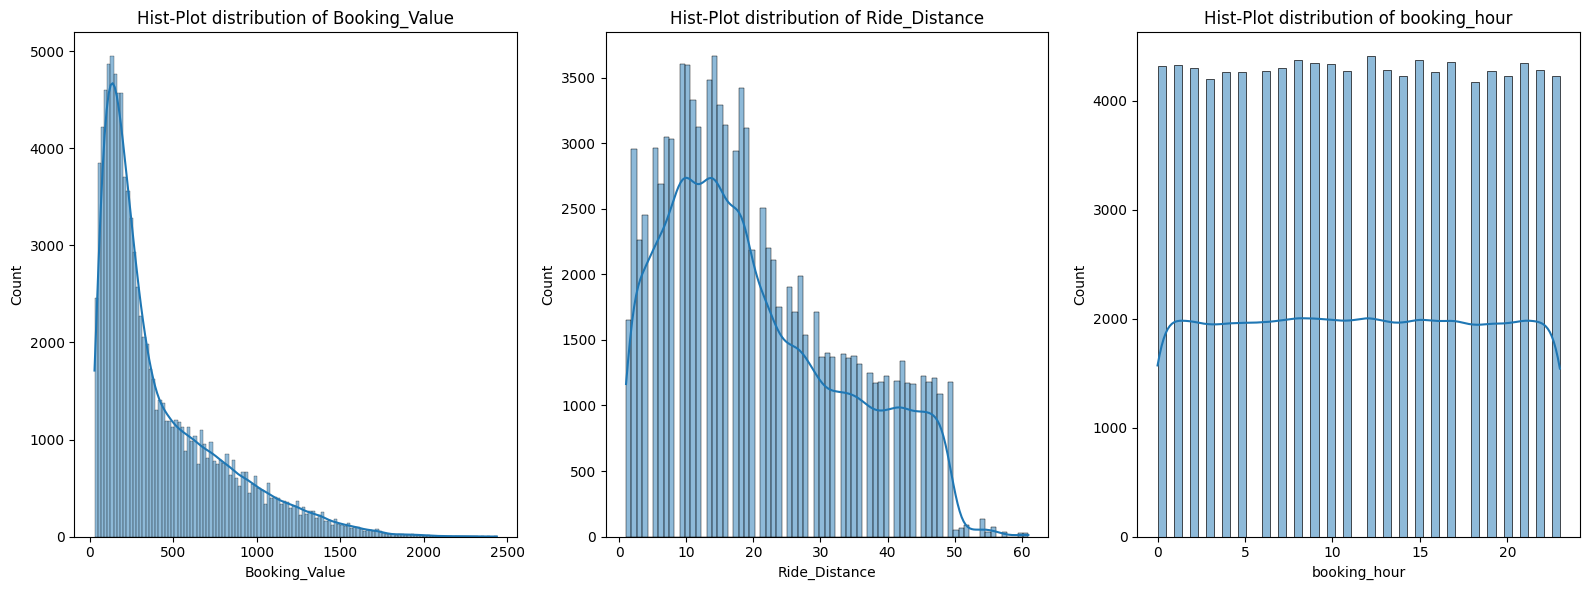

In [33]:
fig,axes = plt.subplots(1,3,figsize=(16,6))
axes = axes.flatten()
for i , col in enumerate(num_cols):
    sns.histplot(data = df,x =col,kde=True,ax=axes[i])
    axes[i].set_title(f"Hist-Plot distribution of {col}")
plt.tight_layout()
plt.show()

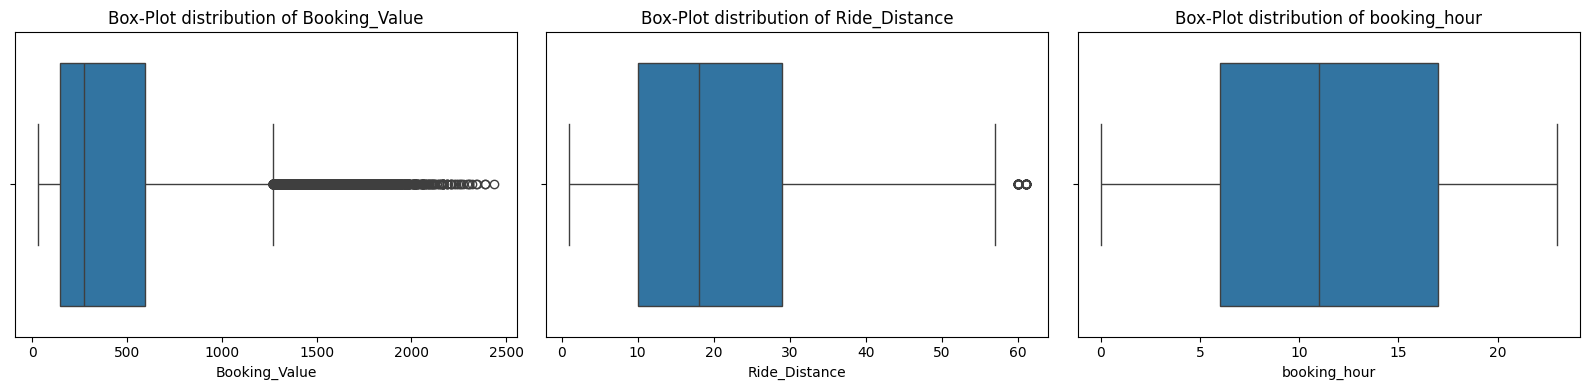

In [34]:
fig, axes = plt.subplots(1,3,figsize=(16,4))
axes = axes.flatten()
for i , col in enumerate(num_cols):
    sns.boxplot(data = df,x =col,ax=axes[i])
    axes[i].set_title(f"Box-Plot distribution of {col}")
plt.tight_layout()
plt.show()

In [35]:
for cols in cat_cols:
    print(f'{cols} : {df[cols].nunique()}')

Vehicle_Type : 7
Weather : 4
booking_dayofweek : 7
office_hour : 2
is_weekend : 2


In [36]:
for cols in cat_cols:
    print(f"{'-'*20} {cols} {'-'*20}")
    print(df[cols].value_counts())

-------------------- Vehicle_Type --------------------
Vehicle_Type
Prime Sedan    14877
eBike          14815
Auto           14754
Prime Plus     14707
Bike           14662
Prime SUV      14655
Mini           14552
Name: count, dtype: int64
-------------------- Weather --------------------
Weather
Light Rain    44841
Cloudy        42715
Clear          9892
Heavy Rain     5574
Name: count, dtype: int64
-------------------- booking_dayofweek --------------------
booking_dayofweek
Tuesday      16925
Monday       16728
Wednesday    16434
Friday       13345
Saturday     13341
Thursday     13236
Sunday       13013
Name: count, dtype: int64
-------------------- office_hour --------------------
office_hour
No     68635
Yes    34387
Name: count, dtype: int64
-------------------- is_weekend --------------------
is_weekend
No     76668
Yes    26354
Name: count, dtype: int64


## Categorical 

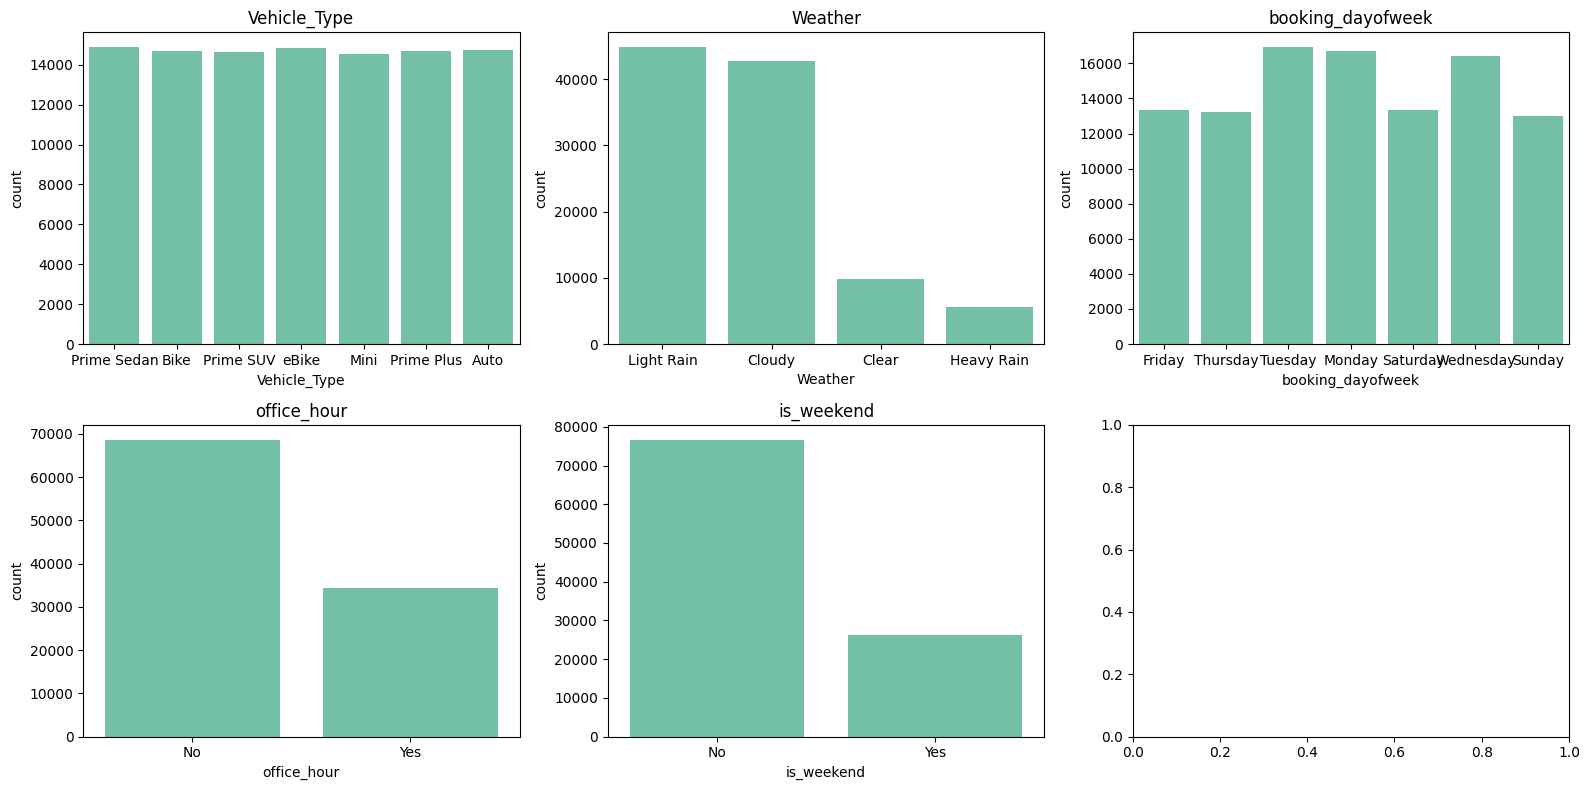

In [37]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    
    sns.countplot(data=df, x=col,color='mediumaquamarine', legend=False, ax=axes[i])
    axes[i].set_title(col)

plt.tight_layout() 
plt.show()

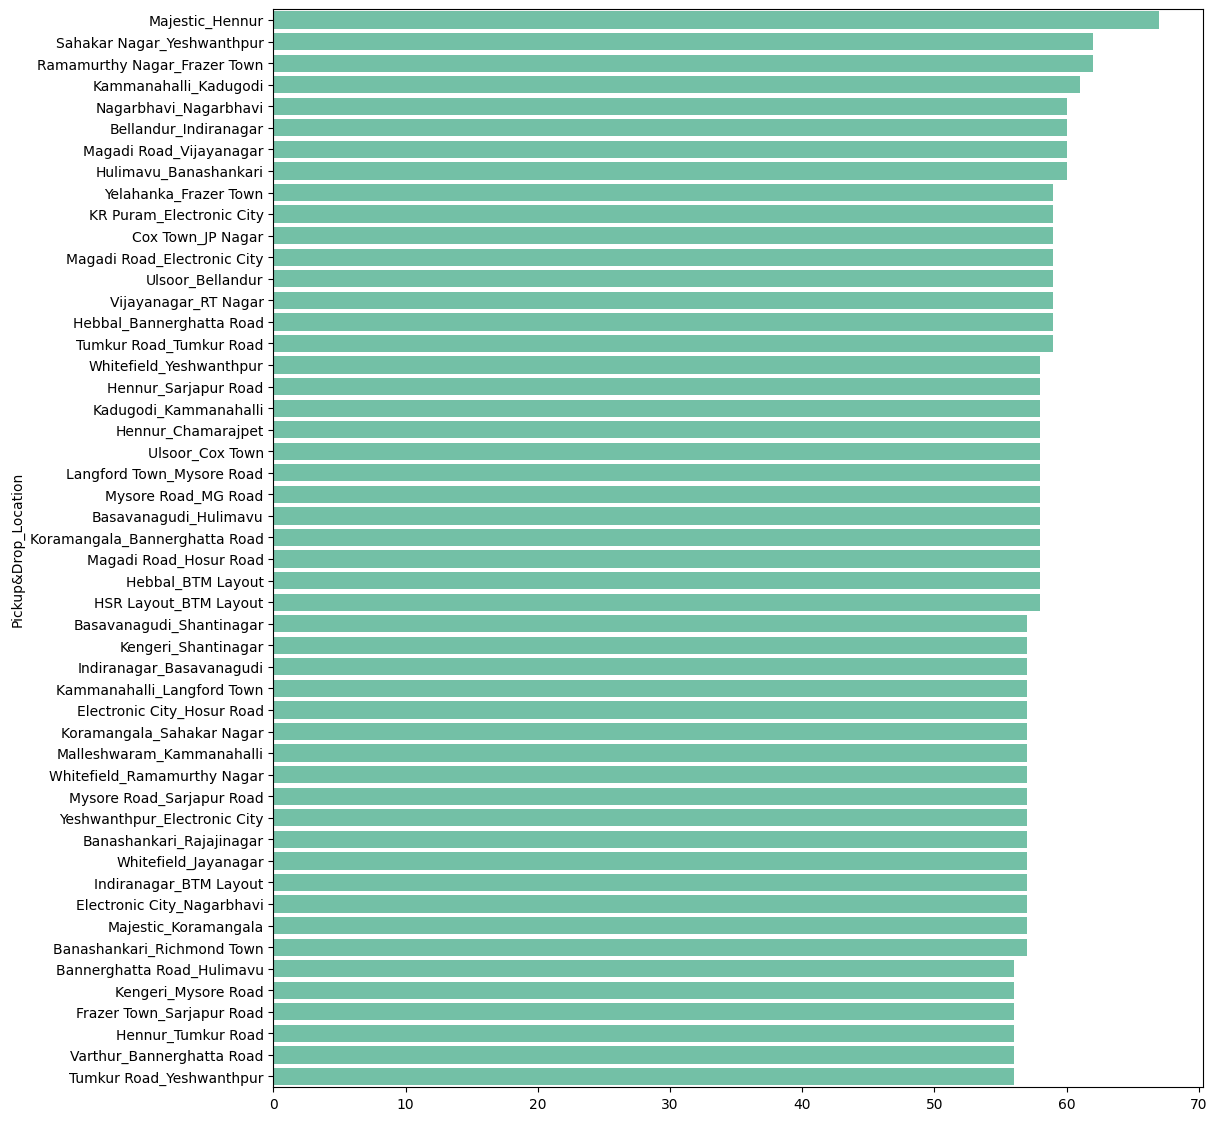

In [38]:
plt.figure(figsize=(12, 14))
series = df['Pickup&Drop_Location'].value_counts()[:50]

sns.barplot(x=series.values,y = series.index,color='mediumaquamarine', legend=False)

plt.show()

# Bivariate Analysis

##  Numerical vs Numerical

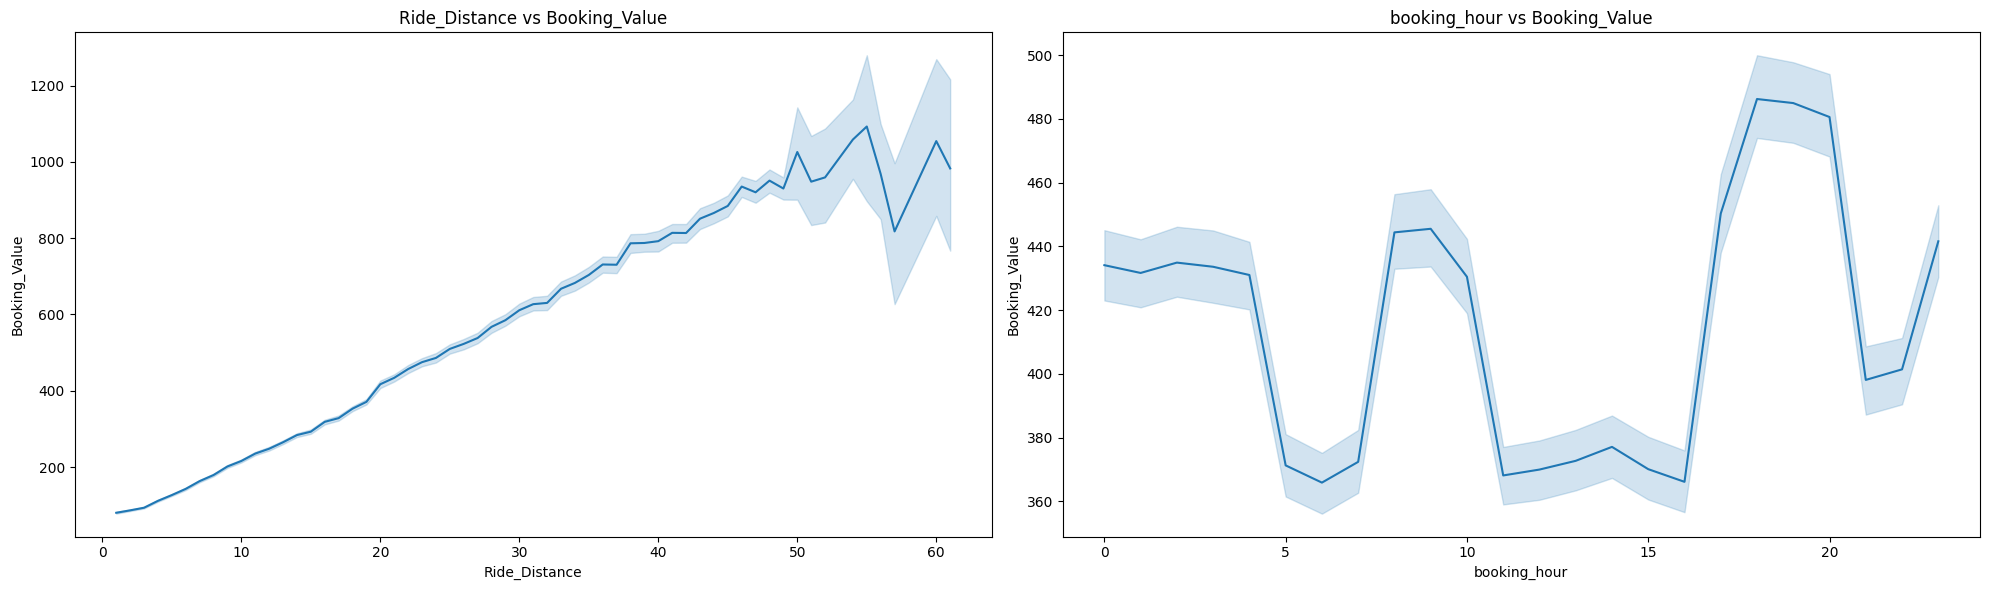

In [39]:
fig, ax = plt.subplots(1,2,figsize=(20,6))
ax = ax.flatten()

## y-variable for each x-variable and shows a confidence interval.
sns.lineplot(data=df, x='Ride_Distance', y='Booking_Value', ax=ax[0])
ax[0].set_title('Ride_Distance vs Booking_Value')

sns.lineplot(data=df, x='booking_hour', y='Booking_Value', ax=ax[1])
ax[1].set_title('booking_hour vs Booking_Value')

plt.tight_layout()
plt.show()

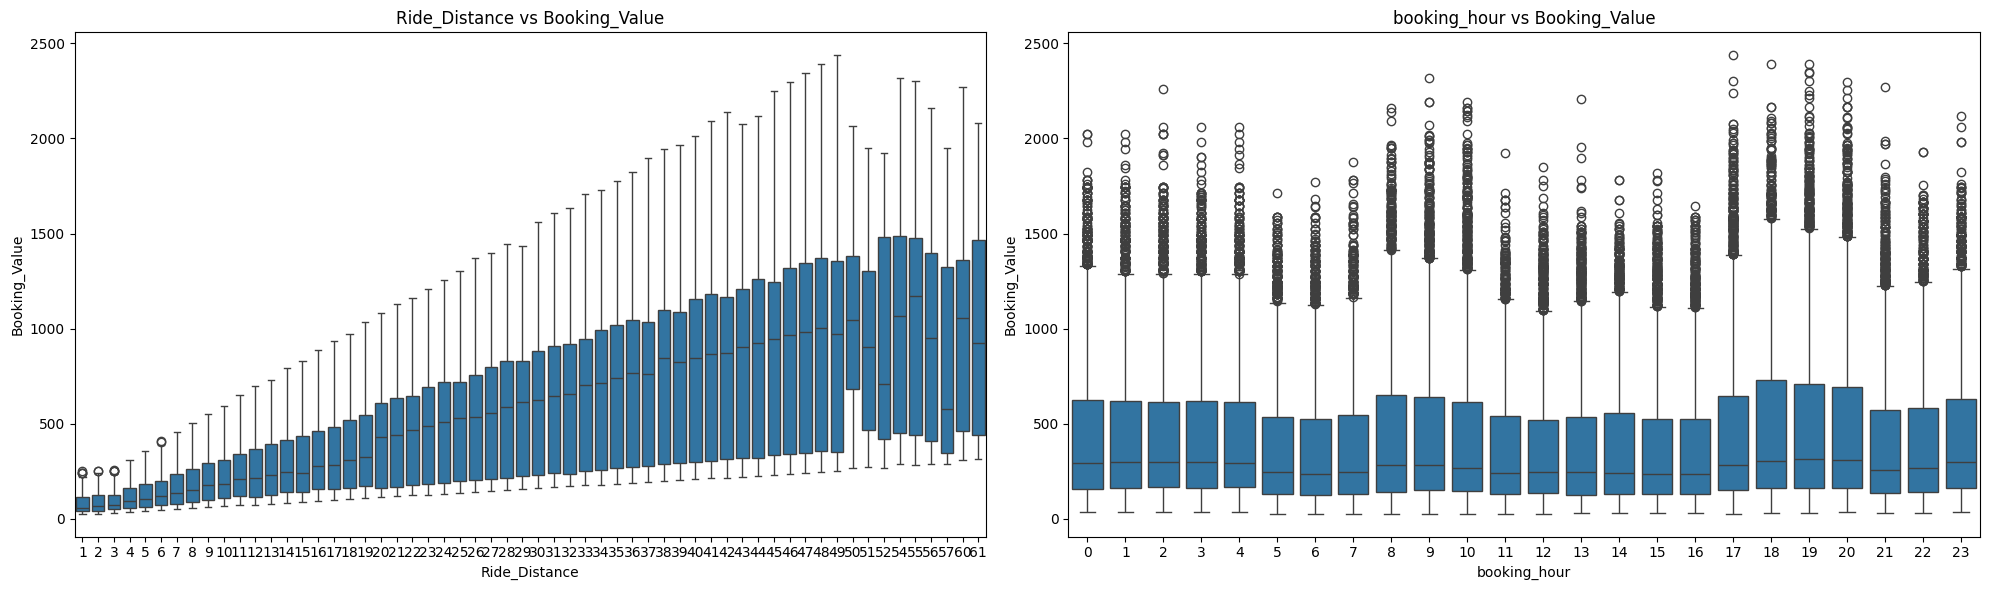

In [40]:
fig, ax = plt.subplots(1,2,figsize=(20,6))
ax = ax.flatten()

sns.boxplot(data=df, x='Ride_Distance', y='Booking_Value', ax=ax[0])
ax[0].set_title('Ride_Distance vs Booking_Value')

sns.boxplot(data=df, x='booking_hour', y='Booking_Value', ax=ax[1])
ax[1].set_title('booking_hour vs Booking_Value')

plt.tight_layout()
plt.show()

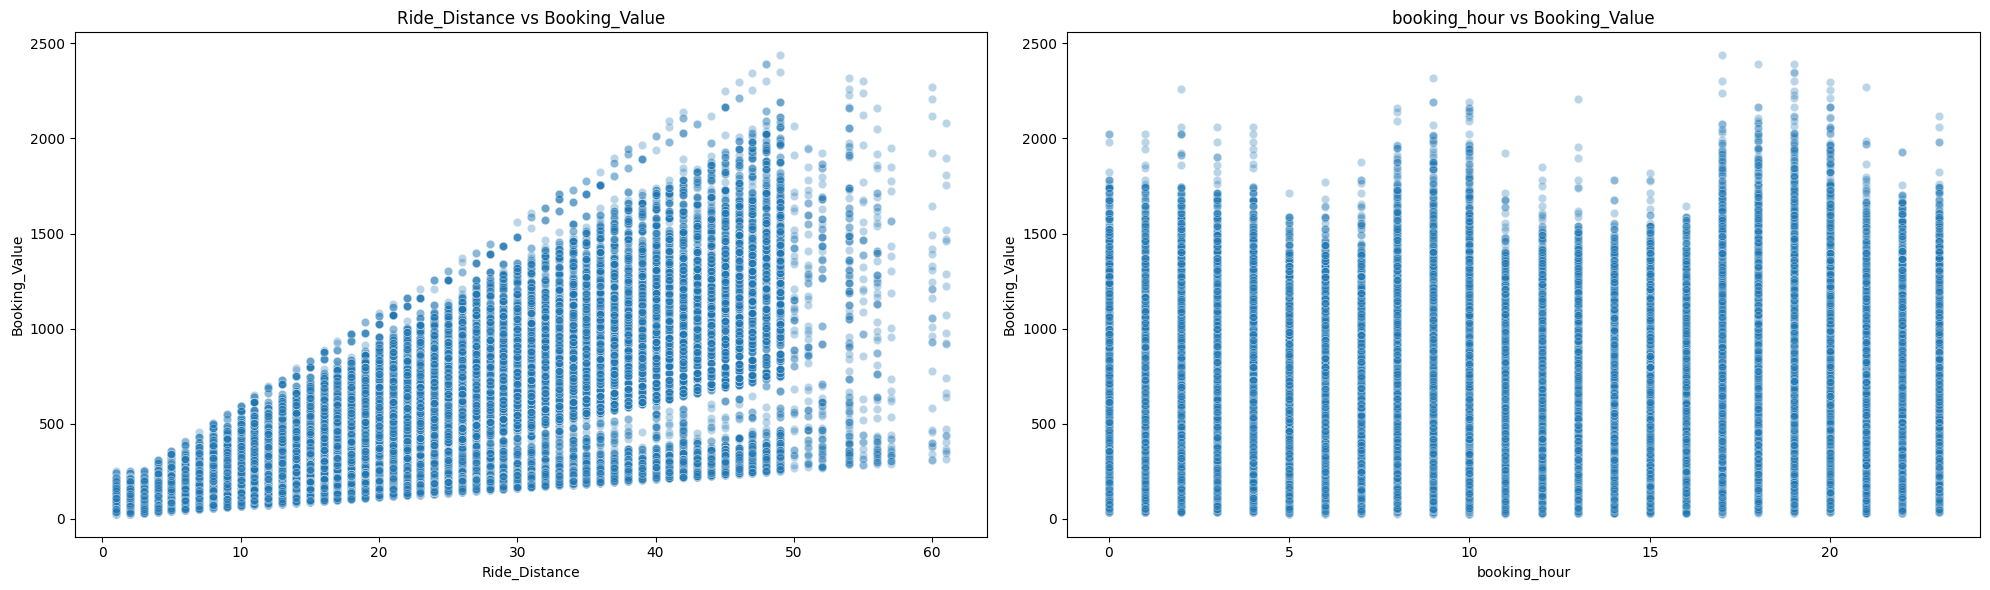

In [41]:
fig, ax = plt.subplots(1,2,figsize=(20,6))
ax = ax.flatten()

sns.scatterplot(data=df, x='Ride_Distance', y='Booking_Value', alpha= 0.3,ax=ax[0])
ax[0].set_title('Ride_Distance vs Booking_Value')

sns.scatterplot(data=df, x='booking_hour', y='Booking_Value',  alpha= 0.3,ax=ax[1])
ax[1].set_title('booking_hour vs Booking_Value')

plt.tight_layout()
plt.show()

## Categorical vs Numerical

### * Booking_Value vs Categorical Variable 

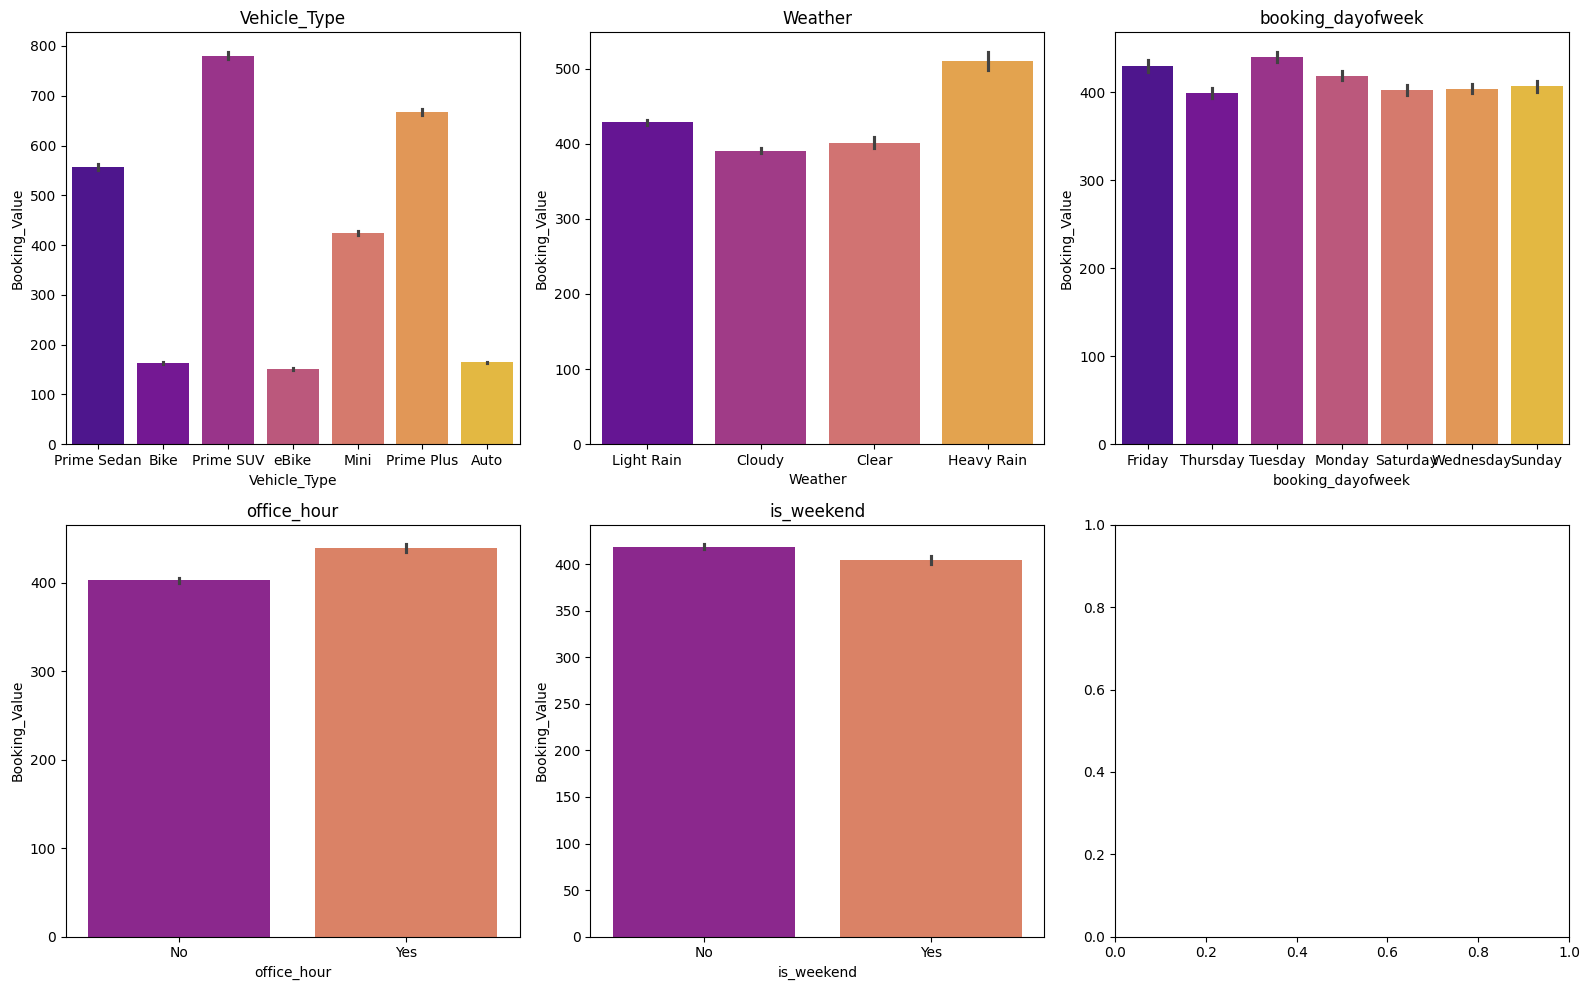

In [42]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    
    sns.barplot(data = df,x=col , y ='Booking_Value',hue = col,legend=False, palette= 'plasma',ax =axes[i])
    axes[i].set_title(col)

plt.tight_layout() 
plt.show()

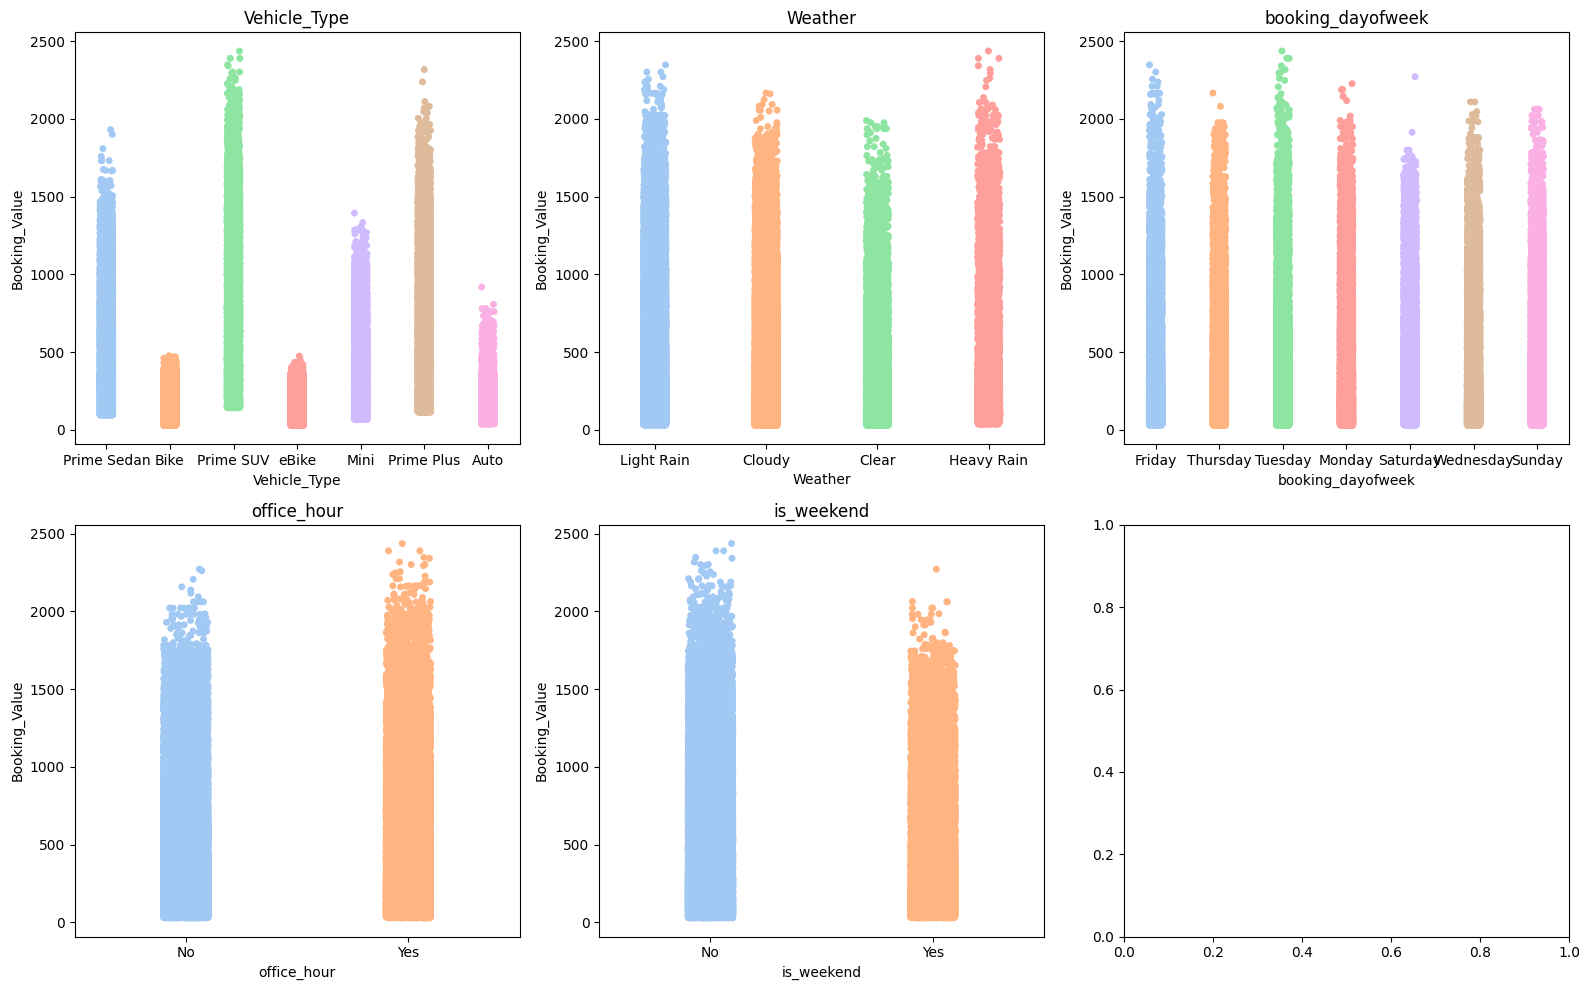

In [43]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    
    sns.stripplot(data = df,x=col , y ='Booking_Value',hue = col,legend=False, palette= 'pastel',ax =axes[i])
    axes[i].set_title(col)

plt.tight_layout() 
plt.show()

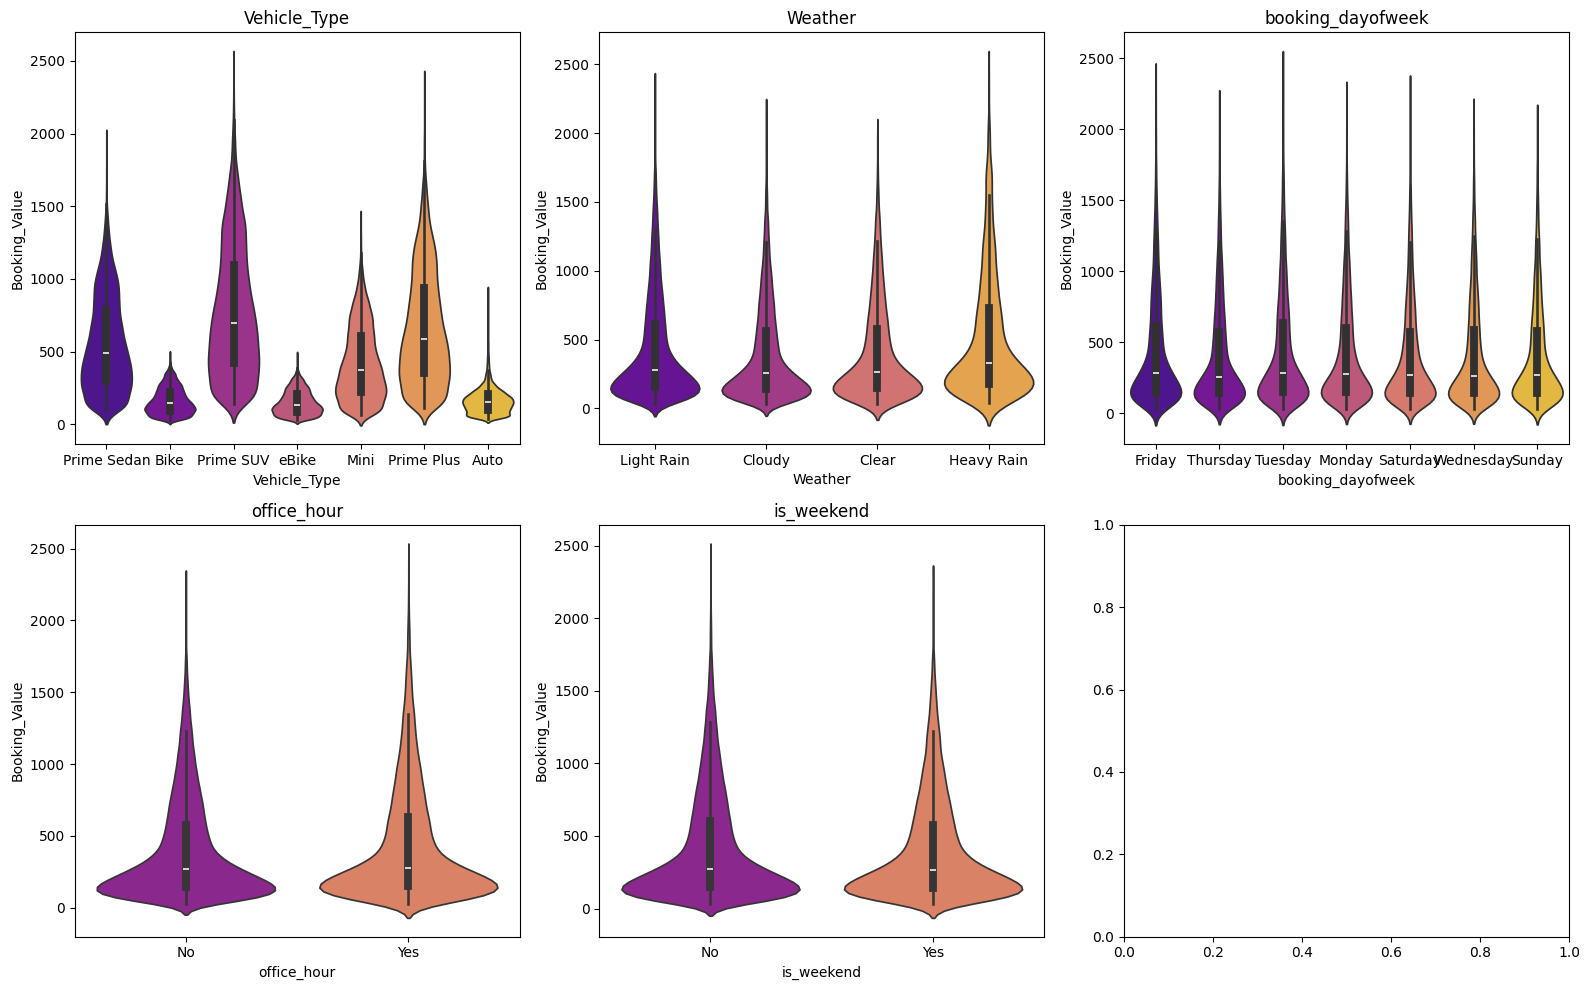

In [44]:
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_cols):
    
    sns.violinplot(data = df,x=col , y ='Booking_Value',hue = col,legend=False, palette= 'plasma',ax =axes[i])
    axes[i].set_title(col)

plt.tight_layout() 
plt.show()

C:\Users\SAYAN\AppData\Local\Temp\ipykernel_1528\2217554542.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_routes.values, y=top_routes.index, palette='viridis')


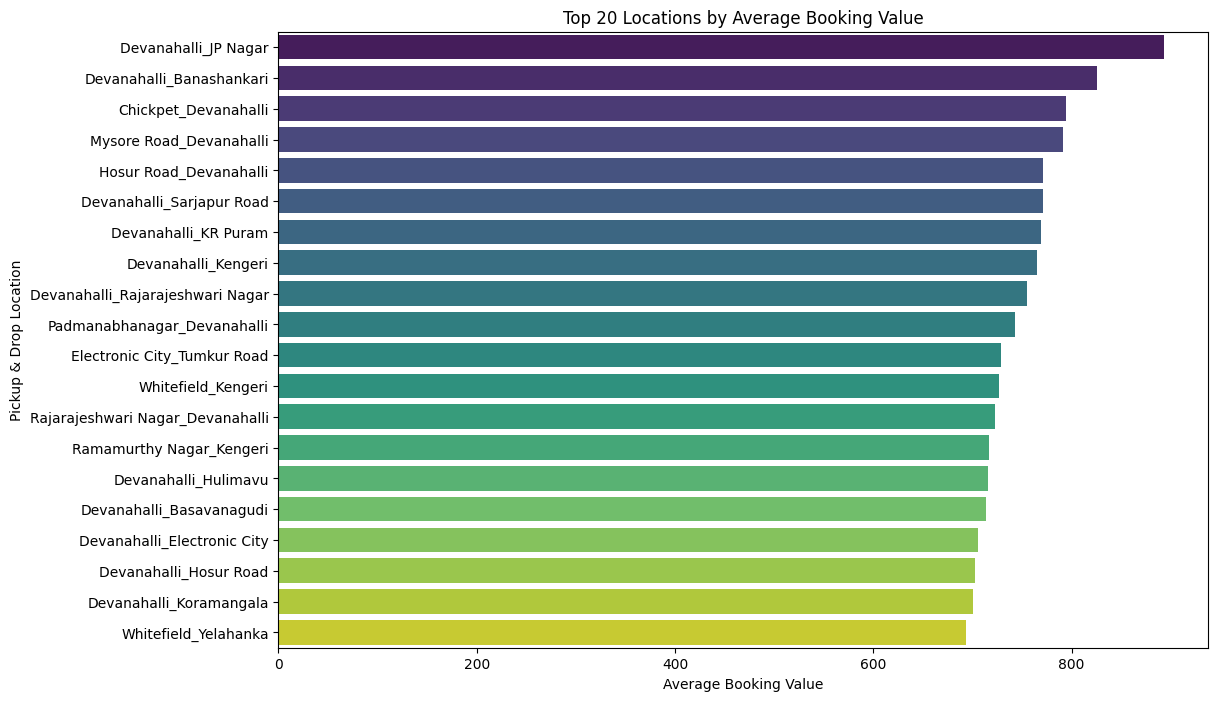

In [45]:
plt.figure(figsize=(12, 8))
# Calculate, sort, and get top 20
top_routes = df.groupby('Pickup&Drop_Location')['Booking_Value'].mean().sort_values(ascending=False).head(20)

sns.barplot(x=top_routes.values, y=top_routes.index, palette='viridis')
plt.title('Top 20 Locations by Average Booking Value')
plt.xlabel('Average Booking Value')
plt.ylabel('Pickup & Drop Location')
plt.show()

C:\Users\SAYAN\AppData\Local\Temp\ipykernel_1528\577802571.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_routes.values, y=top_routes.index, palette='viridis')


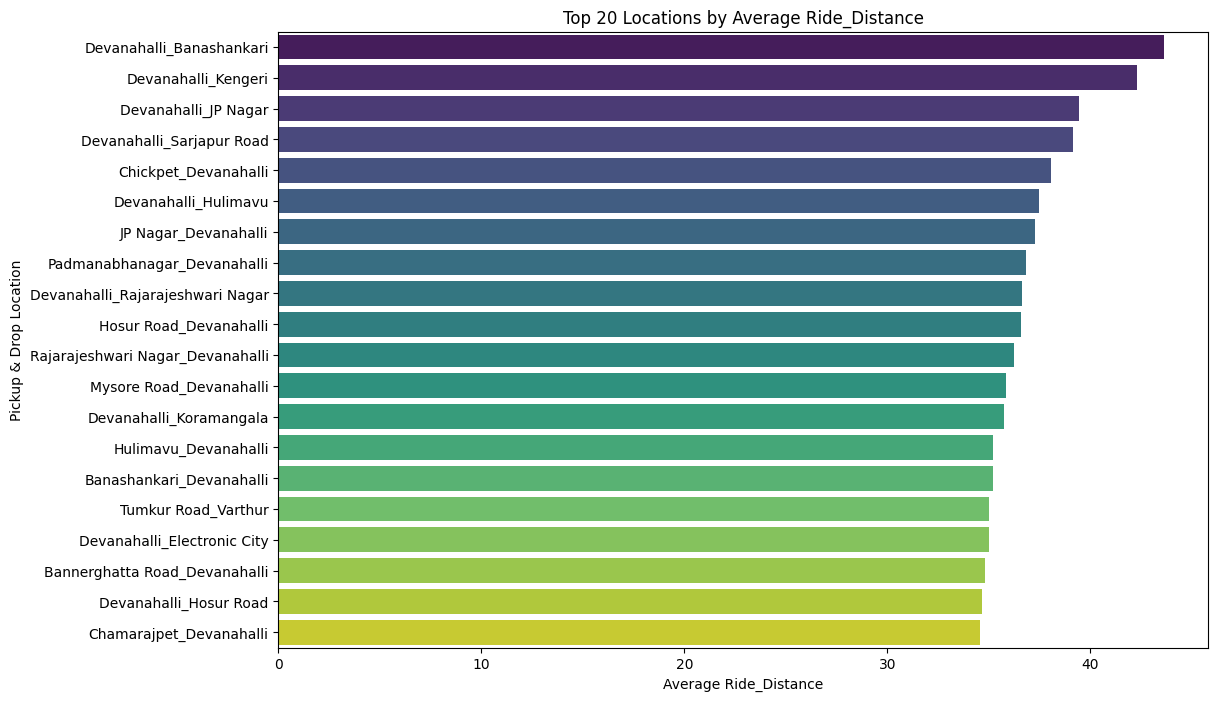

In [46]:
plt.figure(figsize=(12, 8))
# Calculate, sort, and get top 20
top_routes = df.groupby('Pickup&Drop_Location')['Ride_Distance'].mean().sort_values(ascending=False).head(20)

sns.barplot(x=top_routes.values, y=top_routes.index, palette='viridis')
plt.title('Top 20 Locations by Average Ride_Distance')
plt.xlabel('Average Ride_Distance')
plt.ylabel('Pickup & Drop Location')
plt.show()

In [47]:
# 1. Identify the top 30 most frequent routes
top_30_routes = df['Pickup&Drop_Location'].value_counts().head(30).index

# 2. Filter the dataframe to only include these top 30 routes
df_top_routes = df[df['Pickup&Drop_Location'].isin(top_30_routes)]

In [48]:
df_top_routes.head()

,Date,Vehicle_Type,Weather,Booking_Value,Ride_Distance,booking_hour,booking_dayofweek,office_hour,is_weekend,Pickup&Drop_Location
20,2024-07-11 20:42:00,eBike,Clear,237,34,20,Thursday,Yes,No,Basavanagudi_Hulimavu
57,2024-07-25 10:57:00,Mini,Cloudy,261,11,10,Thursday,Yes,No,Hennur_Chamarajpet
97,2024-07-26 08:22:00,Bike,Light Rain,334,44,8,Friday,No,No,Magadi Road_Electronic City
100,2024-07-21 08:21:00,Auto,Cloudy,92,8,8,Sunday,No,Yes,Ulsoor_Bellandur
169,2024-07-04 08:50:00,Prime Plus,Clear,165,3,8,Thursday,No,No,Bellandur_Indiranagar


In [49]:
df_top_routes.shape

(1774, 10)

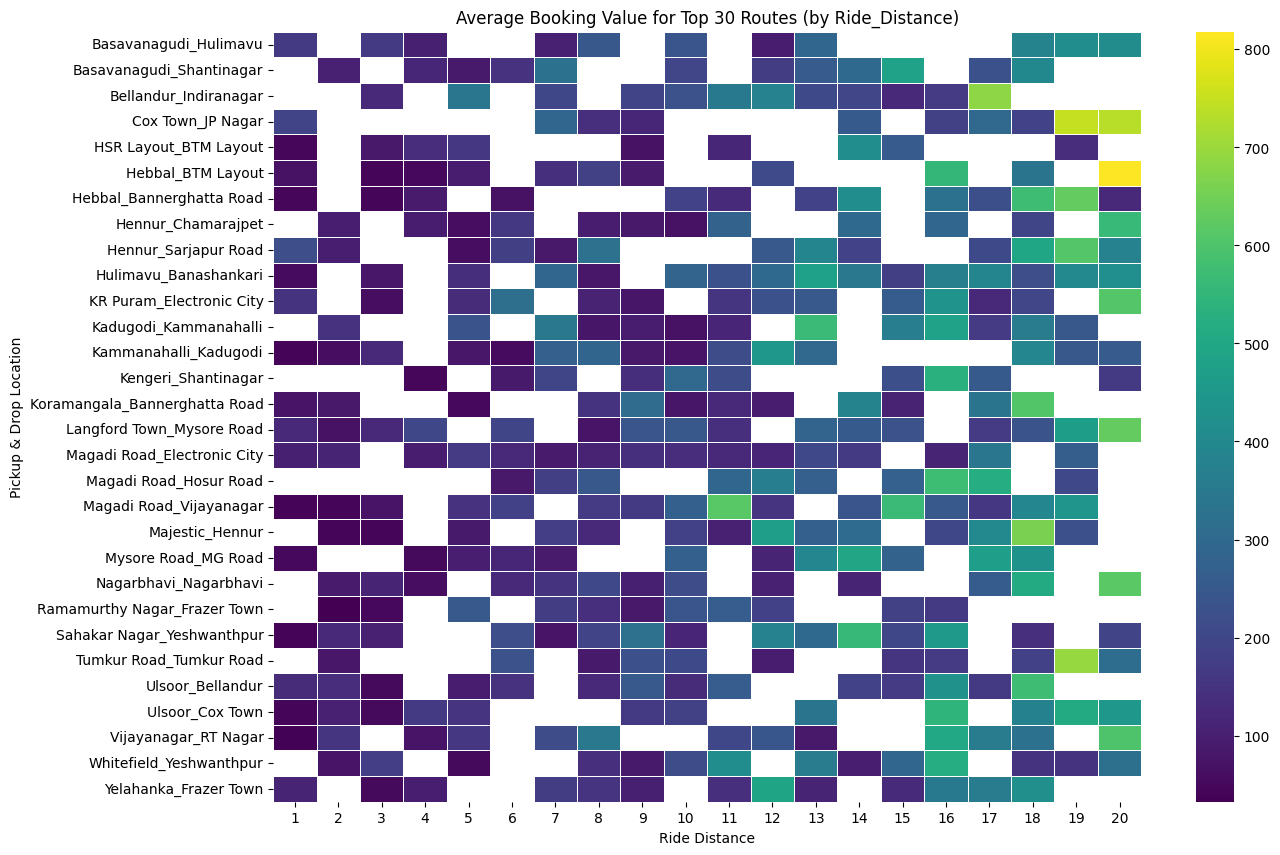

In [50]:
heatmap_data = df_top_routes.pivot_table(
    index='Pickup&Drop_Location', 
    columns='Ride_Distance', 
    values='Booking_Value', 
    aggfunc='mean'
).iloc[:, :20]

plt.figure(figsize=(14, 10))
sns.heatmap(heatmap_data, cmap='viridis', annot=False, linewidths=0.5)
plt.title('Average Booking Value for Top 30 Routes (by Ride_Distance)')
plt.xlabel('Ride Distance')
plt.ylabel('Pickup & Drop Location')
plt.show()

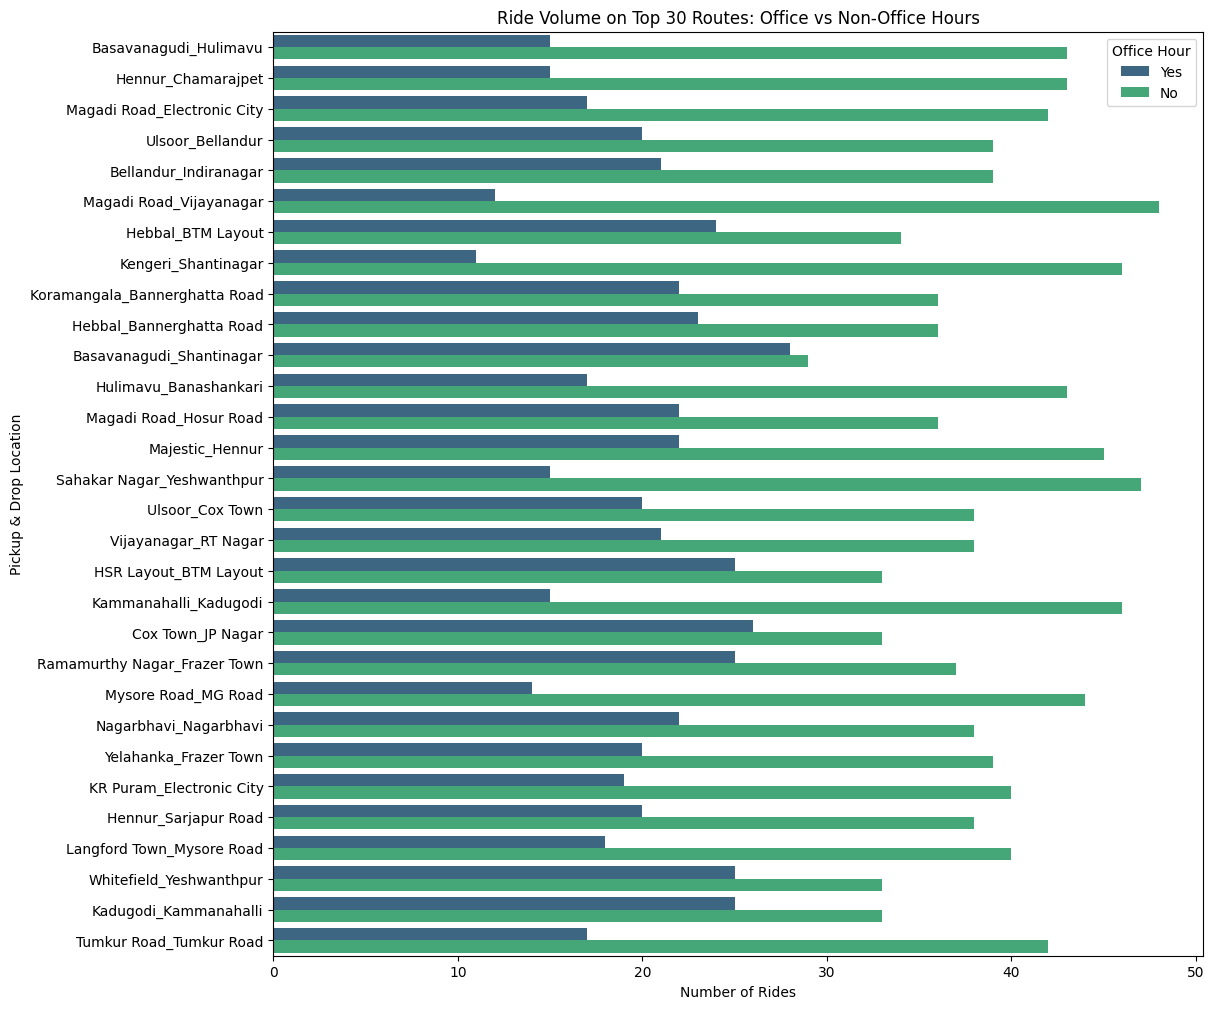

In [51]:
plt.figure(figsize=(12, 12))
sns.countplot(
    data=df_top_routes, 
    y='Pickup&Drop_Location', 
    hue='office_hour', 
    palette='viridis'
)
plt.title('Ride Volume on Top 30 Routes: Office vs Non-Office Hours')
plt.xlabel('Number of Rides')
plt.ylabel('Pickup & Drop Location')
plt.legend(title='Office Hour', loc='upper right')
plt.show()

## Categorical vs Categorical

In [52]:
df.head()

,Date,Vehicle_Type,Weather,Booking_Value,Ride_Distance,booking_hour,booking_dayofweek,office_hour,is_weekend,Pickup&Drop_Location
0,2024-07-26 14:00:00,Prime Sedan,Light Rain,389,16,14,Friday,No,No,Tumkur Road_RT Nagar
1,2024-07-25 22:20:00,Bike,Cloudy,94,13,22,Thursday,No,No,Magadi Road_Varthur
2,2024-07-30 19:59:00,Prime SUV,Cloudy,1547,40,19,Tuesday,Yes,No,Sahakar Nagar_Varthur
3,2024-07-22 03:15:00,eBike,Clear,138,18,3,Monday,No,No,HSR Layout_Vijayanagar
4,2024-07-02 09:02:00,Mini,Light Rain,1056,45,9,Tuesday,Yes,No,Rajajinagar_Chamarajpet


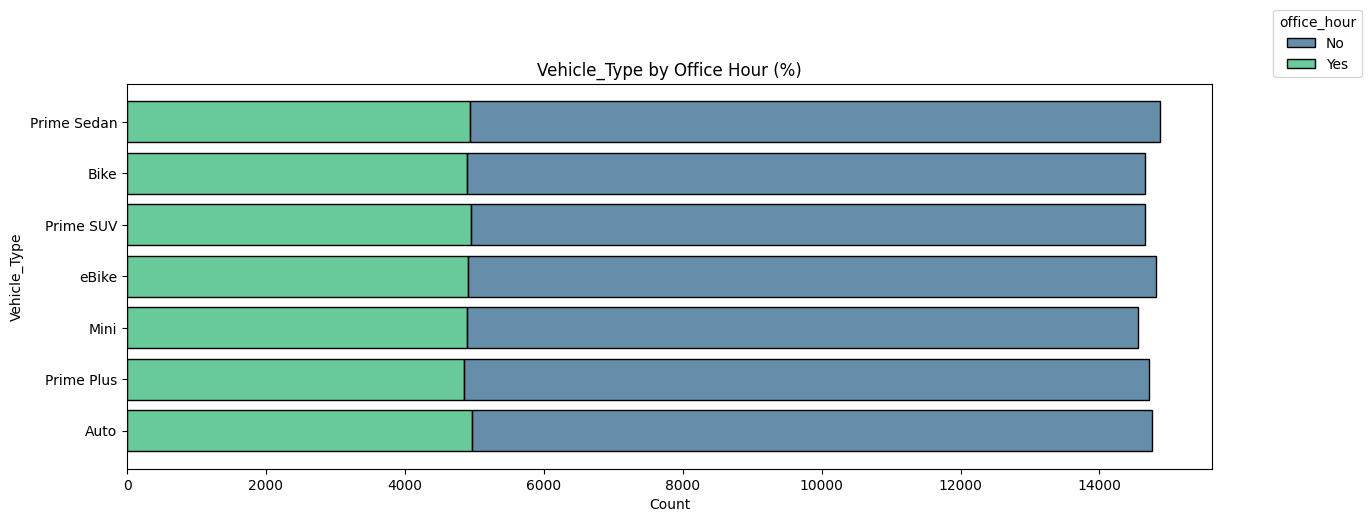

In [53]:
plt.figure(figsize=(14, 5))
ax = sns.histplot(data=df, y='Vehicle_Type', hue='office_hour', multiple='stack', palette='viridis', shrink=0.8)
plt.title('Vehicle_Type by Office Hour (%)')
sns.move_legend(ax, "lower left", bbox_to_anchor=(1.05, 1))
plt.show()

<Axes: xlabel='office_hour', ylabel='Vehicle_Type'>

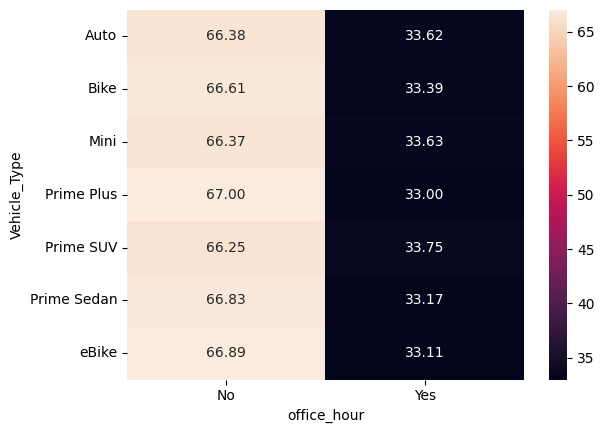

In [56]:
pivot_status_1 = pd.crosstab(df['Vehicle_Type'], df['office_hour'],normalize='index') * 100
sns.heatmap(pivot_status_1, annot=True, fmt='.2f')

# Multivariate Analysis

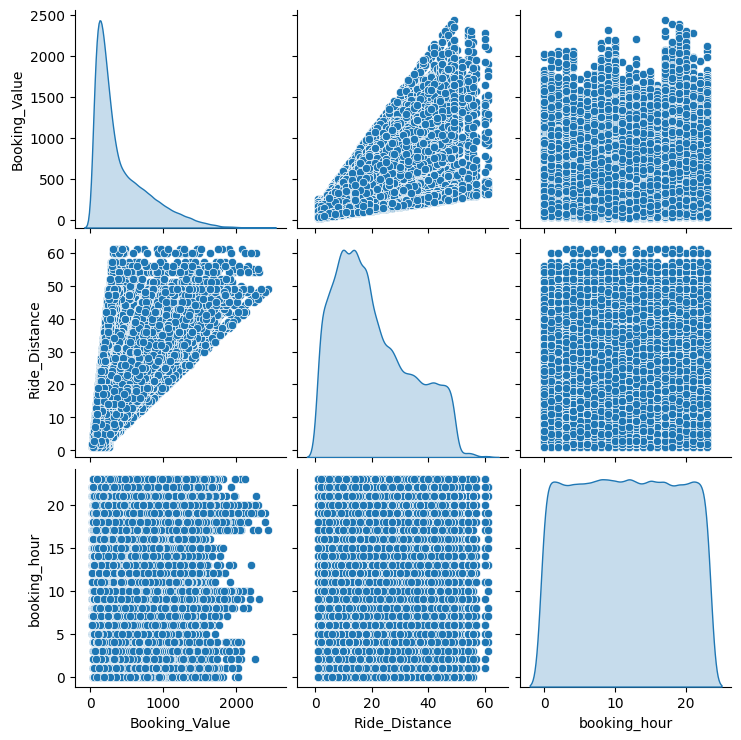

In [66]:
sns.pairplot(df.select_dtypes(np.number),  diag_kind="kde")

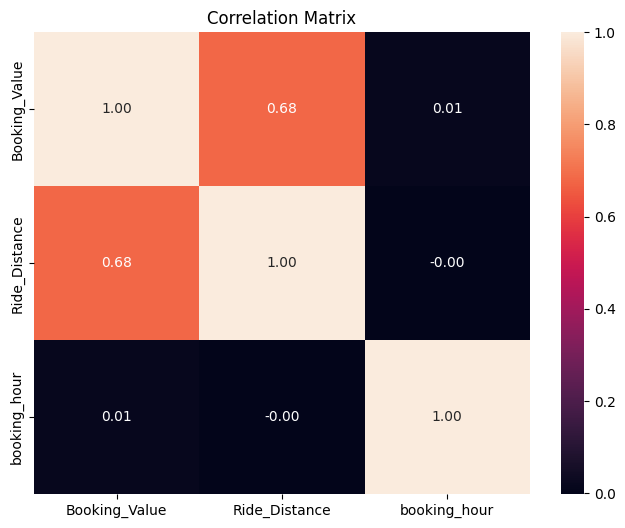

In [67]:
plt.figure(figsize=(8, 6))
sns.heatmap(df.select_dtypes('number').corr(), annot=True, fmt=".2f")
plt.title('Correlation Matrix')
plt.show()